In [1]:
import os, time
from pyspark.sql import SparkSession

BASE = os.path.expanduser("~/bosch-bigdata")

spark = (SparkSession.builder
         .appName("BoschBigData")
         .master("local[*]")
         .config("spark.driver.memory", "5g")
         .config("spark.sql.shuffle.partitions", "64")
         .getOrCreate())

print(spark.version)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/10/14 11:31:27 WARN Utils: Your hostname, Vamoussa, resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/10/14 11:31:27 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/14 11:31:28 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


4.2.0


In [2]:
from pyspark.sql.types import StructType, StructField, DoubleType, IntegerType, StringType

def schema_pour(nom):
    entete = open(f"{BASE}/data/raw/{nom}.csv").readline().strip().split(",")
    champs = []
    for col in entete:
        if col in ("Id", "Response"):
            champs.append(StructField(col, IntegerType()))
        elif nom == "train_categorical":
            champs.append(StructField(col, StringType()))
        else:
            champs.append(StructField(col, DoubleType()))
    return StructType(champs)

In [3]:
fichiers = ["train_numeric", "train_categorical", "train_date"]

for nom in fichiers:
    debut = time.time()
    df = (spark.read
          .option("header", True)
          .schema(schema_pour(nom))
          .csv(f"{BASE}/data/raw/{nom}.csv"))
    df.write.mode("overwrite").parquet(f"{BASE}/data/parquet/{nom}")
    print(f"{nom} : {len(df.columns)} colonnes, {round(time.time() - debut)} secondes")

26/10/14 11:33:51 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.
                                                                                

train_numeric : 970 colonnes, 122 secondes


train_categorical : 2141 colonnes, 226 secondes


[Stage 2:======================================================>  (21 + 1) / 22]

train_date : 1157 colonnes, 179 secondes


In [4]:
#tailles
!du -sh {BASE}/data/raw/*.csv {BASE}/data/parquet/*

2.5G	/home/diaba/bosch-bigdata/data/raw/train_categorical.csv
2.7G	/home/diaba/bosch-bigdata/data/raw/train_date.csv
2.0G	/home/diaba/bosch-bigdata/data/raw/train_numeric.csv
59M	/home/diaba/bosch-bigdata/data/parquet/train_categorical
908M	/home/diaba/bosch-bigdata/data/parquet/train_date
261M	/home/diaba/bosch-bigdata/data/parquet/train_numeric


In [5]:
#temps de lecture
for nom in fichiers:
    t = time.time()
    spark.read.option("header", True).schema(schema_pour(nom)) \
         .csv(f"{BASE}/data/raw/{nom}.csv").select("Id").count()
    t_csv = time.time() - t

    t = time.time()
    spark.read.parquet(f"{BASE}/data/parquet/{nom}").select("Id").count()
    t_pq = time.time() - t

    print(f"{nom} : CSV {t_csv:.1f} s | Parquet {t_pq:.1f} s")

train_numeric : CSV 2.2 s | Parquet 0.8 s


train_categorical : CSV 1.7 s | Parquet 0.5 s


train_date : CSV 1.5 s | Parquet 0.4 s


In [6]:
#aperçu du fichier numérique
num = spark.read.parquet(f"{BASE}/data/parquet/train_numeric")
print("Lignes :", num.count(), "| Colonnes :", len(num.columns))
num.select("Id", "L0_S0_F0", "L0_S0_F2", "L0_S0_F4", "Response").show(5)

Lignes : 1183747 | Colonnes : 970
+-------+--------+--------+--------+--------+
|     Id|L0_S0_F0|L0_S0_F2|L0_S0_F4|Response|
+-------+--------+--------+--------+--------+
|1040837|  -0.173|  -0.161|  -0.033|       0|
|1040839|  -0.173|  -0.161|  -0.033|       0|
|1040840|    NULL|    NULL|    NULL|       0|
|1040844|  -0.016|  -0.019|  -0.179|       0|
|1040848|    NULL|    NULL|    NULL|       0|
+-------+--------+--------+--------+--------+
only showing top 5 rows


In [7]:
#répartition de la variable cible
repartition = num.groupBy("Response").count().orderBy("Response")
repartition.show()

total = num.count()
for r in repartition.collect():
    print(f"Response = {r['Response']} : {r['count']} pièces ({100 * r['count'] / total:.2f} %)")

+--------+-------+
|Response|  count|
+--------+-------+
|       0|1176868|
|       1|   6879|
+--------+-------+

Response = 0 : 1176868 pièces (99.42 %)
Response = 1 : 6879 pièces (0.58 %)


/home/diaba/bosch-env/lib/python3.10/site-packages/pyspark/sql/pandas/conversion.py:348: UserWarning: toPandas attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  [PACKAGE_NOT_INSTALLED] PyArrow >= 18.0.0 must be installed; however, it was not found.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


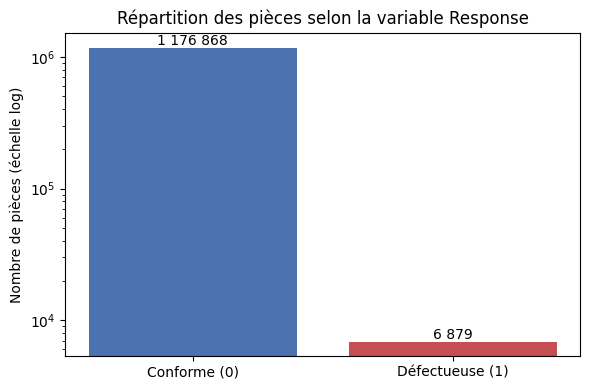

In [8]:
#graphique

import matplotlib.pyplot as plt

pdf = repartition.toPandas()
etiquettes = ["Conforme (0)", "Défectueuse (1)"]

plt.figure(figsize=(6, 4))
barres = plt.bar(etiquettes, pdf["count"], color=["#4C72B0", "#C44E52"])
plt.yscale("log")
plt.ylabel("Nombre de pièces (échelle log)")
plt.title("Répartition des pièces selon la variable Response")
for b, v in zip(barres, pdf["count"]):
    plt.text(b.get_x() + b.get_width() / 2, v, f"{v:,}".replace(",", " "),
             ha="center", va="bottom")
plt.tight_layout()
plt.show()